In [1]:
from pathlib import Path
from scipy.io import loadmat

# =========================
# 1. 设置文件路径
# =========================
mat_path = Path(r"D:\raw_data\kilosort2\kilosort2\development\kilosort2\2953_5month.mat")

# =========================
# 2. 读取 MAT 文件
# =========================
data = loadmat(mat_path)

# =========================
# 3. 查看文件中有哪些变量
# =========================
print("MAT 文件中的变量：")

for key, value in data.items():
    # MATLAB 自带的元信息变量暂时忽略
    if not key.startswith("__"):
        print(
            f"{key:20s} "
            f"type={type(value)}, "
            f"shape={getattr(value, 'shape', None)}, "
            f"dtype={getattr(value, 'dtype', None)}"
        )

MAT 文件中的变量：
units                type=<class 'numpy.ndarray'>, shape=(1, 7), dtype=object
locations            type=<class 'numpy.ndarray'>, shape=(1020, 2), dtype=float64
fs                   type=<class 'numpy.ndarray'>, shape=(1, 1), dtype=float64


In [8]:
from scipy.io import loadmat
import numpy as np

mat_path = r"D:\raw_data\kilosort2\kilosort2\development\kilosort2\2953_5month.mat"

data = loadmat(
    mat_path,
    squeeze_me=True,
    struct_as_record=False
)

units = data["units"]
locations = data["locations"]
fs = float(data["fs"])

print("Sampling rate:", fs)
print("Number of units:", len(units))
print("Locations:", locations.shape)

for i, unit in enumerate(units):

    print(f"\n{'='*20} Unit {i} {'='*20}")
    print("type:", type(unit))

    if hasattr(unit, "_fieldnames"):

        print("fields:", unit._fieldnames)

        for field in unit._fieldnames:

            value = getattr(unit, field)

            print(
                f"{field:20s}"
                f" type={type(value)},"
                f" shape={np.shape(value)},"
                f" dtype={getattr(value, 'dtype', None)}"
            )

    else:
        print("shape:", np.shape(unit))
        print(unit)

Sampling rate: 20000.0
Number of units: 7
Locations: (1020, 2)

==================== Unit 0 ====================
type: <class 'scipy.io.matlab._mio5_params.mat_struct'>
fields: ['spike_train', 'x_max', 'y_max', 'electrode', 'template', 'unit_id']
spike_train          type=<class 'numpy.ndarray'>, shape=(59,), dtype=int64
x_max                type=<class 'float'>, shape=(), dtype=None
y_max                type=<class 'float'>, shape=(), dtype=None
electrode            type=<class 'int'>, shape=(), dtype=None
template             type=<class 'numpy.ndarray'>, shape=(1020, 120), dtype=float32
unit_id              type=<class 'int'>, shape=(), dtype=None

==================== Unit 1 ====================
type: <class 'scipy.io.matlab._mio5_params.mat_struct'>
fields: ['spike_train', 'x_max', 'y_max', 'electrode', 'template', 'unit_id']
spike_train          type=<class 'numpy.ndarray'>, shape=(30,), dtype=int64
x_max                type=<class 'float'>, shape=(), dtype=None
y_max            

In [32]:
print(units[5].spike_train.shape)

(5211,)


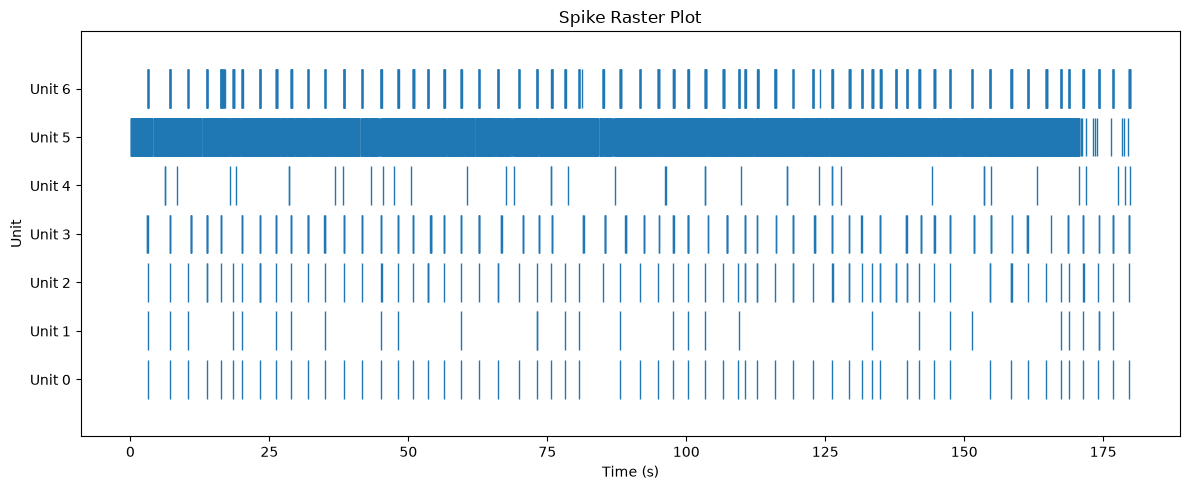

In [21]:
spike_times = [
    np.asarray(unit.spike_train) / fs
    for unit in units
]
import numpy as np
import matplotlib.pyplot as plt

# spike sample → seconds
spike_times = [
    np.asarray(unit.spike_train) / fs
    for unit in units
]

fig, ax = plt.subplots(figsize=(12, 5))

ax.eventplot(
    spike_times,
    lineoffsets=np.arange(len(units)),
    linelengths=0.8,
    linewidths=1
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Unit")
ax.set_yticks(np.arange(len(units)))
ax.set_yticklabels([
    f"Unit {unit.unit_id}"
    for unit in units
])

ax.set_title("Spike Raster Plot")

plt.tight_layout()
plt.show()

In [26]:
waveforms = []

for unit in units:

    # unit 的主位置
    target = np.array([
        unit.x_max,
        unit.y_max
    ])

    # 找最近的 location
    idx = np.argmin(
        np.sum(
            (locations - target) ** 2,
            axis=1
        )
    )

    # 对应 waveform
    waveform = unit.template[idx, :]

    waveforms.append(waveform)

    print(
        f"Unit {unit.unit_id}: "
        f"location index={idx}, "
        f"location={locations[idx]}, "
        f"x_max/y_max=({unit.x_max}, {unit.y_max})"
    )

Unit 0: location index=128, location=[577.5 122.5], x_max/y_max=(577.5, 122.5)
Unit 1: location index=128, location=[577.5 122.5], x_max/y_max=(577.5, 122.5)
Unit 2: location index=128, location=[577.5 122.5], x_max/y_max=(577.5, 122.5)
Unit 3: location index=82, location=[507.5 962.5], x_max/y_max=(507.5, 962.5)
Unit 4: location index=376, location=[682.5 472.5], x_max/y_max=(682.5, 472.5)
Unit 5: location index=670, location=[1522.5 1802.5], x_max/y_max=(1522.5, 1802.5)
Unit 6: location index=732, location=[1172.5  122.5], x_max/y_max=(1172.5, 122.5)


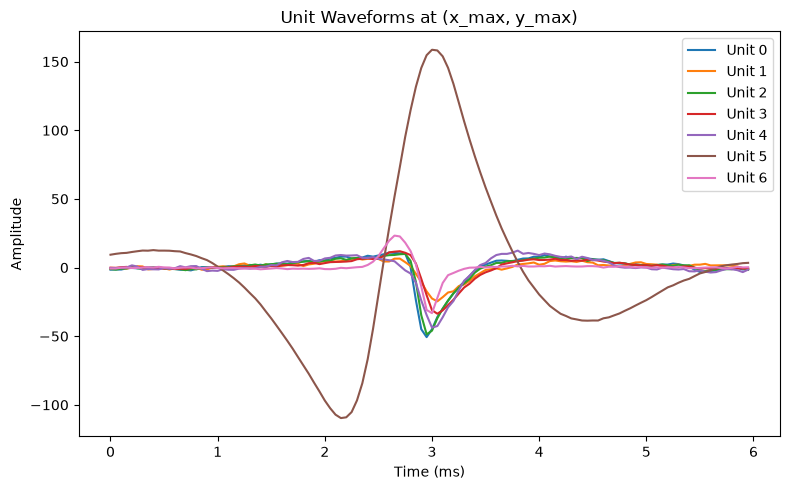

In [27]:
time_ms = (
    np.arange(units[0].template.shape[1])
    / fs
    * 1000
)

fig, ax = plt.subplots(figsize=(8, 5))

for unit, waveform in zip(units, waveforms):

    ax.plot(
        time_ms,
        waveform,
        linewidth=1.5,
        label=f"Unit {unit.unit_id}"
    )

ax.set_xlabel("Time (ms)")
ax.set_ylabel("Amplitude")
ax.set_title("Unit Waveforms at (x_max, y_max)")
ax.legend()

plt.tight_layout()
plt.show()

In [33]:
unit = units[5]

# 方法1：x_max/y_max 对应位置
target = np.array([unit.x_max, unit.y_max])

idx_xy = np.argmin(
    np.sum((locations - target)**2, axis=1)
)

# 方法2：template 中 PTP 最大的位置
ptp = np.ptp(unit.template, axis=1)
idx_ptp = np.argmax(ptp)

print("Unit ID:", unit.unit_id)
print("electrode ID:", unit.electrode)

print("\nx_max/y_max:")
print(unit.x_max, unit.y_max)

print("\nXY index:", idx_xy)
print("XY location:", locations[idx_xy])
print("XY PTP:", ptp[idx_xy])

print("\nMax PTP index:", idx_ptp)
print("Max PTP location:", locations[idx_ptp])
print("Max PTP:", ptp[idx_ptp])

Unit ID: 5
electrode ID: 22747

x_max/y_max:
1522.5 1802.5

XY index: 670
XY location: [1522.5 1802.5]
XY PTP: 268.27826

Max PTP index: 670
Max PTP location: [1522.5 1802.5]
Max PTP: 268.27826


In [34]:
unit = units[5]

spike_times = np.asarray(unit.spike_train) / fs
isi_ms = np.diff(spike_times) * 1000

duration = spike_times.max() - spike_times.min()

print("Number of spikes:", len(spike_times))
print("First spike:", spike_times.min(), "s")
print("Last spike:", spike_times.max(), "s")

print(
    "Rate between first-last spike:",
    len(spike_times) / duration,
    "Hz"
)

print("Minimum ISI:", isi_ms.min(), "ms")

print(
    "ISI < 1 ms:",
    np.sum(isi_ms < 1),
    f"({np.mean(isi_ms < 1)*100:.2f}%)"
)

print(
    "ISI < 2 ms:",
    np.sum(isi_ms < 2),
    f"({np.mean(isi_ms < 2)*100:.2f}%)"
)

print(
    "Median ISI:",
    np.median(isi_ms),
    "ms"
)

Number of spikes: 5211
First spike: 0.03275 s
Last spike: 179.39325 s
Rate between first-last spike: 29.053219633085323 Hz
Minimum ISI: 0.4500000000007276 ms
ISI < 1 ms: 33 (0.63%)
ISI < 2 ms: 70 (1.34%)
Median ISI: 23.175000000007273 ms


In [35]:
unit = units[5]

template = unit.template

ptp = np.ptp(
    template,
    axis=1
)

print("PTP range:")
print(ptp.min(), ptp.max())

PTP range:
0.21545264 268.27826


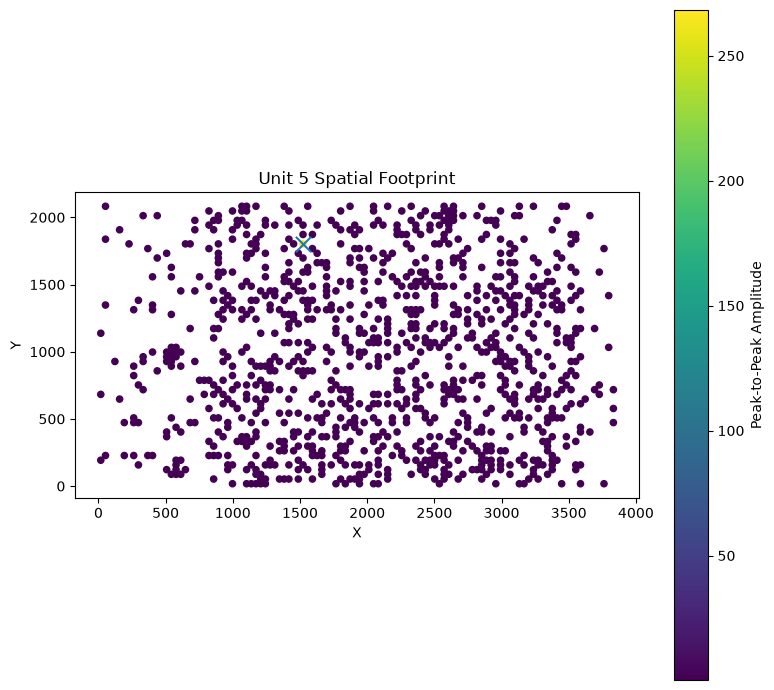

In [36]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))

sc = ax.scatter(
    locations[:, 0],
    locations[:, 1],
    c=ptp,
    s=20
)

ax.scatter(
    unit.x_max,
    unit.y_max,
    s=120,
    marker="x"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Unit 5 Spatial Footprint")

ax.set_aspect("equal")

plt.colorbar(
    sc,
    ax=ax,
    label="Peak-to-Peak Amplitude"
)

plt.tight_layout()
plt.show()

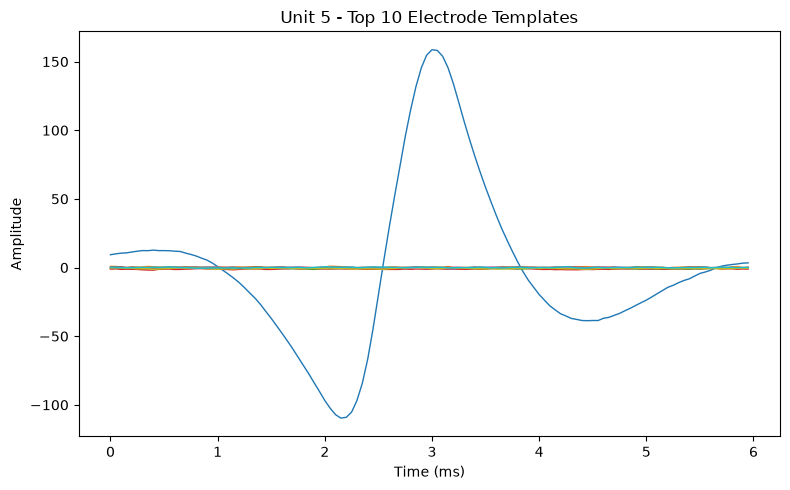

In [37]:
unit = units[5]

template = unit.template
ptp = np.ptp(template, axis=1)

# PTP 最大的 10 个电极
top_idx = np.argsort(ptp)[-10:][::-1]

time_ms = np.arange(template.shape[1]) / fs * 1000

fig, ax = plt.subplots(figsize=(8, 5))

for idx in top_idx:
    ax.plot(
        time_ms,
        template[idx],
        linewidth=1,
        label=f"{idx}"
    )

ax.set_xlabel("Time (ms)")
ax.set_ylabel("Amplitude")
ax.set_title("Unit 5 - Top 10 Electrode Templates")

plt.tight_layout()
plt.show()

In [38]:
for unit in units:

    ptp = np.ptp(unit.template, axis=1)
    order = np.argsort(ptp)[::-1]

    first = ptp[order[0]]
    second = ptp[order[1]]

    print(
        f"Unit {unit.unit_id}: "
        f"max={first:.2f}, "
        f"second={second:.2f}, "
        f"ratio={first/second:.2f}"
    )

Unit 0: max=64.89, second=61.59, ratio=1.05
Unit 1: max=33.50, second=31.51, ratio=1.06
Unit 2: max=59.60, second=58.56, ratio=1.02
Unit 3: max=45.54, second=40.18, ratio=1.13
Unit 4: max=56.11, second=25.04, ratio=2.24
Unit 5: max=268.28, second=1.52, ratio=176.84
Unit 6: max=56.47, second=17.27, ratio=3.27


Mean ISI:   34.426199616122844
Median ISI: 23.175000000007273
Std ISI:    58.61127475623882
ISI CV: 1.7025194593012634


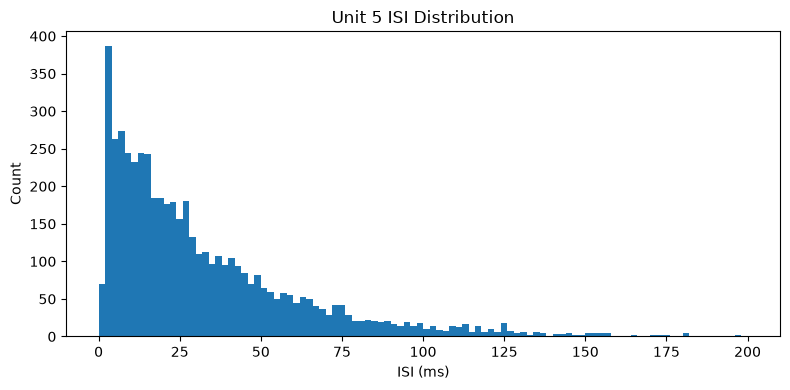

In [39]:
unit = units[5]

spike_times = np.asarray(unit.spike_train) / fs
isi_ms = np.diff(spike_times) * 1000

print("Mean ISI:  ", np.mean(isi_ms))
print("Median ISI:", np.median(isi_ms))
print("Std ISI:   ", np.std(isi_ms))

cv = np.std(isi_ms) / np.mean(isi_ms)

print("ISI CV:", cv)
plt.figure(figsize=(8, 4))

plt.hist(
    isi_ms,
    bins=np.arange(0, 201, 2)
)

plt.xlabel("ISI (ms)")
plt.ylabel("Count")
plt.title("Unit 5 ISI Distribution")

plt.tight_layout()
plt.show()